# EU JRC PVGIS Solar Radiation & Photovoltaic Simulation Pipeline
### A Practical Guide to CM SAF Satellite Solar Irradiance, Photovoltaic System Design, and Typical Meteorological Years (TMY)
**Featuring Dedan Kimathi University of Technology (DeKUT), Nyeri & Pan-Kenyan Solar Benchmark**  
*Part of the `MasharikiWeather` Framework by DeKUT-DSAIL*

---

### Executive Overview
The **Photovoltaic Geographical Information System (PVGIS)** is an open-access scientific service provided by the **European Commission Joint Research Centre (JRC)**. PVGIS combines decades of calibrated geostationary satellite records (**EUMETSAT CM SAF SARAH-3**) and global atmospheric reanalyses (**ECMWF ERA5**) with an advanced physical photovoltaic engineering simulator.

Working with the raw JRC web APIs often presents practical hurdles:
- Managing multiple distinct endpoints (`seriescalc`, `PVcalc`, `tmy`, `MRcalc`, `printhorizon`) with different query schemas.
- Translating technical solar variables (`G(i)`, `Gb(i)`, `Gd(i)`, `Gr(i)`, `H_sun`) into usable data pipelines.
- Multi-year requests requiring manual year-by-year chunking and timestamp re-assembly.
- Handling rate limits (30 req/sec) and API version routing (v5.3 vs v5.2).

`masharikiweather.wrappers.pvgis` unifies all of PVGIS into a streamlined, high-level Python interface:
* **Zero API Key Needed:** Free public REST service provided by the European Commission.
* **Open Data License:** Permitted under the EU Commission Reuse Policy (free for academic, commercial, and open-source applications).
* **Latest EUMETSAT Satellite Data:** Built-in `PVGIS-SARAH3` (0.05° / ~5km resolution covering 2005–2023 across Europe & Africa).
* **Built-in PV Engineering Engine:** Simulate electrical power output ($P$ in Watts), annual yield ($E_y$ in kWh), system loss breakdowns, and automated optimal tilt and azimuth angle discovery.
* **Typical Meteorological Year (TMY):** Instant 1-line generation of 8,760-hour synthetic years for building energy and microgrid simulations.
* **Smart Disk Caching:** Automated Parquet caching ensures fast repeat analyses and zero redundant network overhead.

| Core Method / Tool | Primary Purpose | Key Benefit |
| :--- | :--- | :--- |
| `query_pvgis(...)` | 1-line hourly solar & weather query | Fetches GHI, beam, diffuse, temp, wind, and simulated PV power. |
| `simulate_pvgis_pv(...)` | Grid-connected PV system simulation | Computes annual energy ($E_y$), monthly yield ($E_m$), and optimal tilt/azimuth. |
| `query_pvgis_tmy(...)` | Typical Meteorological Year generator | Produces 8,760-hour TMY dataset for building & microgrid modeling. |
| `PVGIS.horizon(...)` | Topographical shading analyzer | Computes 360-degree horizon shading angle profile based on DEMs. |
| `search_pvgis_parameters()` | Interactive dictionary search | Search variables, view descriptions, and check scientific units. |
| `list_pvgis_databases()` | Satellite database catalog | Lists available satellite and reanalysis backends. |


## 1. Environment Setup & Configuration

We configure our runtime environment, import `masharikiweather`, and set up geospatial coordinates for **Dedan Kimathi University of Technology (DeKUT) in Nyeri, Kenya**.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Visual formatting setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 110

from masharikiweather.wrappers.pvgis import (
    PVGIS,
    query_pvgis,
    simulate_pvgis_pv,
    query_pvgis_tmy,
    search_parameters as search_pvgis_parameters,
    list_databases as list_pvgis_databases,
    PVGIS_DATABASES,
)

# Coordinates for Dedan Kimathi University of Technology (DeKUT), Nyeri, Kenya
# High altitude campus (~1,780m) on the slopes of Mount Kenya & the Aberdare Range
DEKUT_NYERI_LAT = -0.398
DEKUT_NYERI_LON = 36.958
DEKUT_LABEL = "DeKUT_Nyeri"

print(f"MasharikiWeather PVGIS wrapper successfully loaded.")
print(f"Target Campus: Dedan Kimathi University of Technology (Nyeri) @ ({DEKUT_NYERI_LAT}, {DEKUT_NYERI_LON})")
print(f"Available PVGIS radiation databases: {list_pvgis_databases()}")


MasharikiWeather PVGIS wrapper successfully loaded.
Target Campus: Dedan Kimathi University of Technology (Nyeri) @ (-0.398, 36.958)
Available PVGIS radiation databases: ['PVGIS-SARAH3', 'PVGIS-SARAH2', 'PVGIS-ERA5', 'PVGIS-NSRDB']


## 2. Interactive Database & Parameter Discovery

PVGIS provides multiple satellite and reanalysis radiation databases along with dedicated solar and engineering variables. We can explore them interactively in Python.

In [2]:
# 1. Display available radiation databases
db_summary = []
for name, meta in PVGIS_DATABASES.items():
    db_summary.append({
        "database": name,
        "source": meta["source"],
        "coverage": meta["coverage"],
        "resolution": meta["spatial_res"],
        "years": f"{meta['years'][0]} - {meta['years'][1]}"
    })
print("=== Supported PVGIS Radiation Databases ===")
display(pd.DataFrame(db_summary))

# 2. Search parameter dictionary
print("\n=== PVGIS Parameter Catalog ===")
display(search_pvgis_parameters()[["code", "primary_alias", "description", "units"]])


=== Supported PVGIS Radiation Databases ===


,database,source,coverage,resolution,years
0,PVGIS-SARAH3,EUMETSAT CM SAF / Meteosat,"Europe, Africa, parts of South America & Middl...",0.05° (~5 km),2005 - 2023
1,PVGIS-SARAH2,EUMETSAT CM SAF,"Europe, Africa, parts of South America",0.05° (~5 km),2005 - 2020
2,PVGIS-ERA5,ECMWF,Global (Worldwide),0.28° (~31 km),2005 - 2023
3,PVGIS-NSRDB,NREL,North and Central America,4 km,2005 - 2020



=== PVGIS Parameter Catalog ===


,code,primary_alias,description,units
0,G(i),ghi,Global Irradiance on Inclined (or Horizontal) ...,W/m^2
1,Gb(i),dni_horizontal,Direct Beam Irradiance on Inclined (or Horizon...,W/m^2
2,Gd(i),dhi,Diffuse Solar Irradiance on Inclined (or Horiz...,W/m^2
3,Gr(i),refl,Ground Reflected Solar Irradiance on Plane,W/m^2
4,H_sun,sun_elevation,Sun Height / Solar Elevation Angle above Horizon,degrees
5,P,p,Simulated PV System Electric Power Generation,W
6,T2m,t2m,Air Temperature at 2 Meters,°C
7,WS10m,ws10m,Wind Speed at 10 Meters,m/s
8,Int,int,Data Processing & Reconstruction Index (0: nor...,integer code


## 3. Rapid Retrieval: Hourly Solar Radiation (`seriescalc`)

Using `query_pvgis(...)`, we can retrieve hourly satellite-derived solar radiation and surface meteorology for DeKUT, Nyeri in 1–2 lines of code.

Here we query a sample week in **January 2023** using the **`PVGIS-SARAH3`** database (the latest high-resolution EUMETSAT CM SAF satellite generation). The wrapper automatically parses timestamps, standardizes variable aliases (`ghi`, `beam`, `diffuse`, `temp`, `wind`, `sun_elevation`), and caches results locally in fast Parquet format.

In [3]:
# 1-line query for hourly solar radiation & meteorology at DeKUT, Nyeri
df_hourly = query_pvgis(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    start_date="2023-01-01",
    end_date="2023-01-07",
    variables=["ghi", "beam", "diffuse", "temp", "wind", "sun_elevation"],
    database="PVGIS-SARAH3",
    format="wide"
)

# Extract series for DeKUT
loc_col = df_hourly.columns.levels[0][0]
sub_hourly = df_hourly[loc_col]

print(f"Dataset shape: {sub_hourly.shape} (Hours x Variables)")
display(sub_hourly.head(8))


Dataset shape: (168, 6) (Hours x Variables)


variable,beam,diffuse,ghi,sun_elevation,temp,wind
time,,,,,,
2023-01-01 00:05:00+00:00,0.00,0.0,0.00,0.00,9.35,1.52
2023-01-01 01:05:00+00:00,0.00,0.0,0.00,0.00,8.85,1.59
2023-01-01 02:05:00+00:00,0.00,0.0,0.00,0.00,8.45,1.66
2023-01-01 03:05:00+00:00,0.00,0.0,0.00,0.00,8.12,1.66
2023-01-01 04:05:00+00:00,59.00,37.0,96.00,7.14,8.24,1.59
2023-01-01 05:05:00+00:00,287.01,70.0,357.01,20.88,12.74,0.83
2023-01-01 06:05:00+00:00,498.01,99.0,597.01,34.35,16.62,0.69
2023-01-01 07:05:00+00:00,719.01,98.0,817.01,47.21,17.67,1.24


### Plot 1: Hourly Solar Irradiance Decomposition & Solar Height Angle ($H_{sun}$)

Breaking down total global irradiance ($G$) into beam/direct ($Gb$) and diffuse ($Gd$) components alongside the sun elevation angle ($H_{sun}$) across consecutive diurnal cycles.

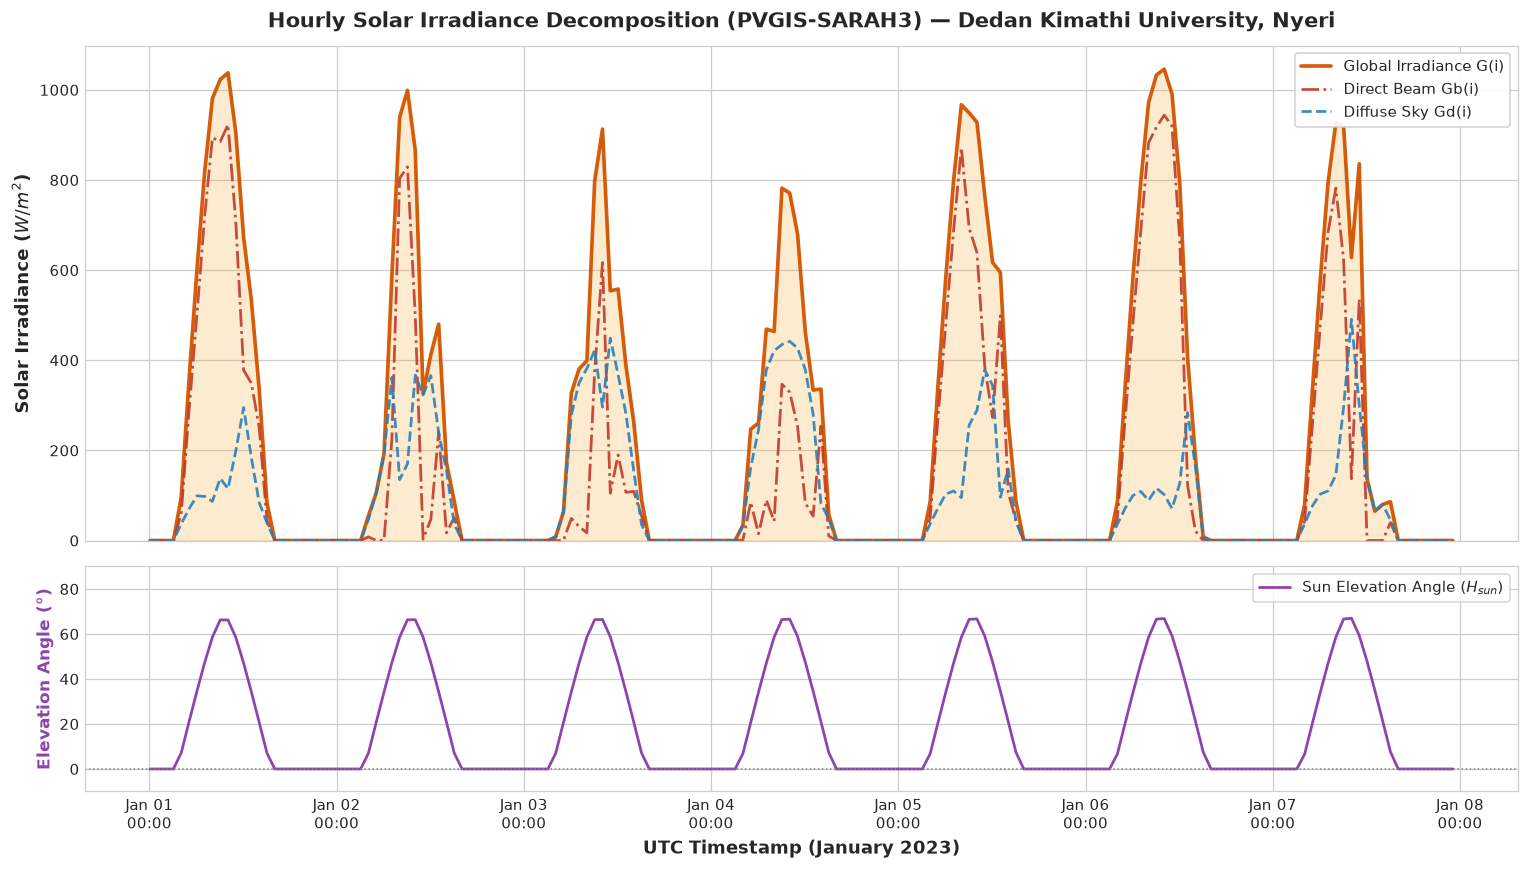

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})

# Upper panel: Solar Irradiance Components
ax1.plot(sub_hourly.index, sub_hourly['ghi'], color='#d35400', linewidth=2.4, label='Global Irradiance G(i)', alpha=0.95)
ax1.plot(sub_hourly.index, sub_hourly['beam'], color='#c0392b', linewidth=1.8, linestyle='-.', label='Direct Beam Gb(i)', alpha=0.9)
ax1.plot(sub_hourly.index, sub_hourly['diffuse'], color='#2980b9', linewidth=1.8, linestyle='--', label='Diffuse Sky Gd(i)', alpha=0.9)
ax1.fill_between(sub_hourly.index, sub_hourly['ghi'], color='#f39c12', alpha=0.2)
ax1.set_ylabel('Solar Irradiance ($W/m^2$)', fontsize=12, fontweight='bold')
ax1.set_title('Hourly Solar Irradiance Decomposition (PVGIS-SARAH3) — Dedan Kimathi University, Nyeri', fontsize=14, fontweight='bold', pad=12)
ax1.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
ax1.set_ylim(bottom=0)

# Lower panel: Sun elevation angle
ax2.plot(sub_hourly.index, sub_hourly['sun_elevation'], color='#8e44ad', linewidth=1.8, label='Sun Elevation Angle ($H_{sun}$)')
ax2.axhline(0, color='gray', linestyle=':', linewidth=1)
ax2.set_ylabel('Elevation Angle (°)', fontsize=11, fontweight='bold', color='#8e44ad')
ax2.set_xlabel('UTC Timestamp (January 2023)', fontsize=12, fontweight='bold')
ax2.set_ylim(-10, 90)
ax2.legend(loc='upper right', frameon=True, facecolor='white')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %d\n%H:%M'))

plt.tight_layout()
plt.show()


## 4. Photovoltaic System Power Simulation (`pvcalculation=True`)

Unlike generic weather APIs, PVGIS features an integrated **photovoltaic engineering engine**. By passing `pvcalculation=True`, the wrapper simulates the physical electricity generated by a solar array:
* `peakpower`: Nominal peak power of the array in kWp (e.g. 1.0 kWp).
* `loss`: Estimated system losses in % (inverter efficiency, cables, dust, dirt; default 14%).
* `optimalinclination=True`: Automatically calculates the optimal tilt angle for maximum solar capture.

Let's simulate a **1.0 kWp photovoltaic array** installed on the DeKUT campus and observe the generated electric power ($P$ in Watts).

In [5]:
# Query hourly data WITH simulated 1 kWp PV electric power generation
df_pv_power = query_pvgis(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    start_date="2023-01-01",
    end_date="2023-01-07",
    variables=["ghi", "beam", "diffuse", "temp", "power"],
    pvcalculation=True,
    peakpower=1.0,          # 1 kWp system
    loss=14.0,              # 14% total system losses
    optimalinclination=True, # Automatically optimize panel tilt
    format="wide"
)

loc_pv = df_pv_power.columns.levels[0][0]
sub_pv = df_pv_power[loc_pv]

print(f"Peak electric power produced during the week: {sub_pv['power'].max():.2f} W (from 1 kWp system)")
display(sub_pv.head(8))


Peak electric power produced during the week: 807.92 W (from 1 kWp system)


variable,beam,diffuse,ghi,power,temp
time,,,,,
2023-01-01 00:05:00+00:00,0.00,0.00,0.00,0.00,9.35
2023-01-01 01:05:00+00:00,0.00,0.00,0.00,0.00,8.85
2023-01-01 02:05:00+00:00,0.00,0.00,0.00,0.00,8.45
2023-01-01 03:05:00+00:00,0.00,0.00,0.00,0.00,8.12
2023-01-01 04:05:00+00:00,64.81,38.22,103.03,53.21,8.24
2023-01-01 05:05:00+00:00,296.72,71.36,368.10,283.42,12.74
2023-01-01 06:05:00+00:00,508.52,100.32,608.87,481.09,16.62
2023-01-01 07:05:00+00:00,730.56,99.10,829.70,647.51,17.67


### Plot 2: Solar Irradiance Input vs. Electrical Power Output & Ambient Temperature
Comparing incident solar radiation ($W/m^2$) against generated electricity ($W$) and ambient temperature ($T2m$) at DeKUT.

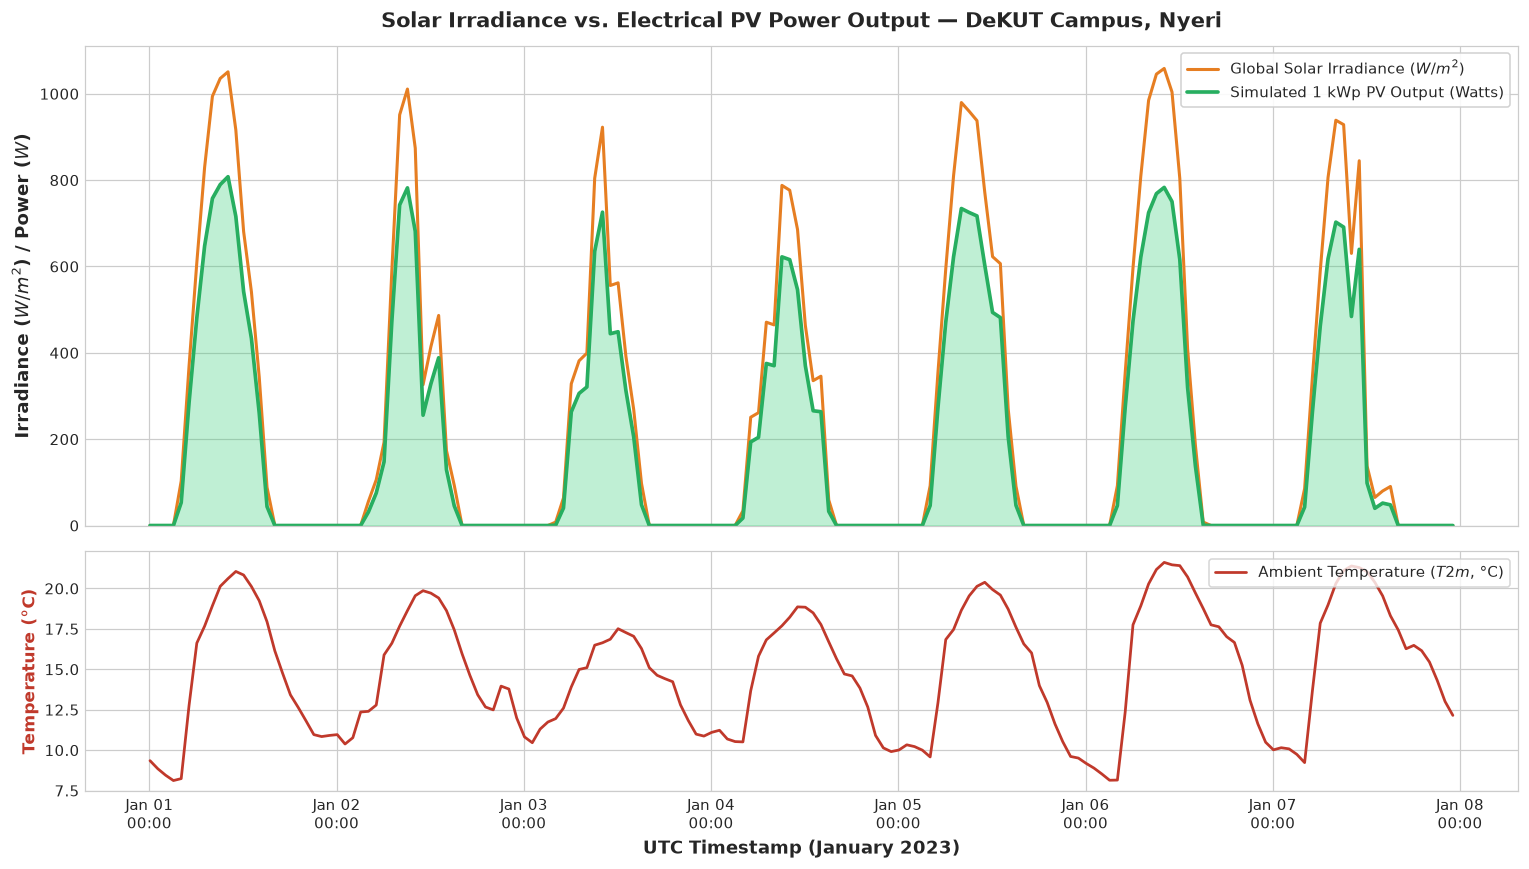

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

# Upper panel: Irradiance vs PV Power output
ax1.plot(sub_pv.index, sub_pv['ghi'], color='#e67e22', linewidth=2.0, label='Global Solar Irradiance ($W/m^2$)')
ax1.plot(sub_pv.index, sub_pv['power'], color='#27ae60', linewidth=2.4, label='Simulated 1 kWp PV Output (Watts)')
ax1.fill_between(sub_pv.index, sub_pv['power'], color='#2ecc71', alpha=0.3)
ax1.set_ylabel('Irradiance ($W/m^2$) / Power ($W$)', fontsize=12, fontweight='bold')
ax1.set_title('Solar Irradiance vs. Electrical PV Power Output — DeKUT Campus, Nyeri', fontsize=14, fontweight='bold', pad=12)
ax1.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
ax1.set_ylim(bottom=0)

# Lower panel: Ambient Temperature
ax2.plot(sub_pv.index, sub_pv['temp'], color='#c0392b', linewidth=1.8, label='Ambient Temperature ($T2m$, °C)')
ax2.set_ylabel('Temperature (°C)', color='#c0392b', fontsize=11, fontweight='bold')
ax2.set_xlabel('UTC Timestamp (January 2023)', fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', frameon=True, facecolor='white')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %d\n%H:%M'))

plt.tight_layout()
plt.show()


## 5. Grid-Connected System Performance & Tilt Optimization (`PVcalc`)

The `PVcalc` tool simulates the complete annual performance of a grid-connected PV system:
* Total annual electricity generation ($E_y$ in kWh/year).
* Average daily energy production ($E_d$ in kWh/day).
* In-plane annual solar irradiation ($H_y$ in $kWh/m^2$).
* Detailed loss breakdown (temperature losses, angle-of-incidence reflection losses, spectral effects).
* **Automatic Discovery of Optimal Tilt (Slope) & Azimuth Orientation.**

Let's simulate a **5.0 kWp commercial rooftop array** at Dedan Kimathi University of Technology.

In [7]:
# Run a complete grid-connected PV system simulation for DeKUT, Nyeri
sim_result = simulate_pvgis_pv(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    peakpower=5.0, # 5 kWp array
    loss=14.0,     # 14% system losses
    optimalangles=True,
    database="PVGIS-SARAH3"
)

totals = sim_result["totals"]
opt_angles = sim_result["optimal_angles"]

print("=== 5 kWp Grid-Connected PV System Simulation Results (DeKUT, Nyeri) ===")
print(f"Annual Electricity Production (Ey) : {totals.get('E_y'):.2f} kWh/year")
print(f"Daily Average Production (Ed)       : {totals.get('E_d'):.2f} kWh/day")
print(f"Annual In-Plane Irradiation (Hy)   : {totals.get('H(i)_y'):.2f} kWh/m^2")
print(f"Total System Losses                : {totals.get('l_total')}%")
print(f"Optimal Panel Tilt Angle (Slope)   : {opt_angles.get('slope', {}).get('value')}°")
print(f"Optimal Azimuth Orientation        : {opt_angles.get('azimuth', {}).get('value')}°")

monthly_yield_df = sim_result["monthly"]
display(monthly_yield_df)


=== 5 kWp Grid-Connected PV System Simulation Results (DeKUT, Nyeri) ===
Annual Electricity Production (Ey) : 3626.13 kWh/year
Daily Average Production (Ed)       : 9.93 kWh/day
Annual In-Plane Irradiation (Hy)   : 971.18 kWh/m^2
Total System Losses                : -25.33%
Optimal Panel Tilt Angle (Slope)   : 89°
Optimal Azimuth Orientation        : -180°


,month,E_d,E_m,H(i)_d,H(i)_m,SD_m
0,1,6.69,207.35,1.84,57.16,20.98
1,2,7.41,207.53,2.07,58.05,16.58
2,3,8.28,256.66,2.27,70.50,22.73
3,4,10.90,327.07,3.05,91.59,13.08
4,5,13.60,421.61,3.61,111.86,12.92
5,6,13.97,419.21,3.60,107.94,27.28
6,7,12.48,386.99,3.22,99.89,25.17
7,8,11.49,356.05,3.04,94.30,18.35
8,9,9.19,275.59,2.49,74.84,16.50
9,10,8.52,264.19,2.26,69.98,17.06


### Plot 3: Monthly PV Electricity Production ($E_m$) & In-Plane Solar Irradiation ($H_m$)
Visualizing the seasonal electricity output of the 5 kWp system across all 12 months at DeKUT.

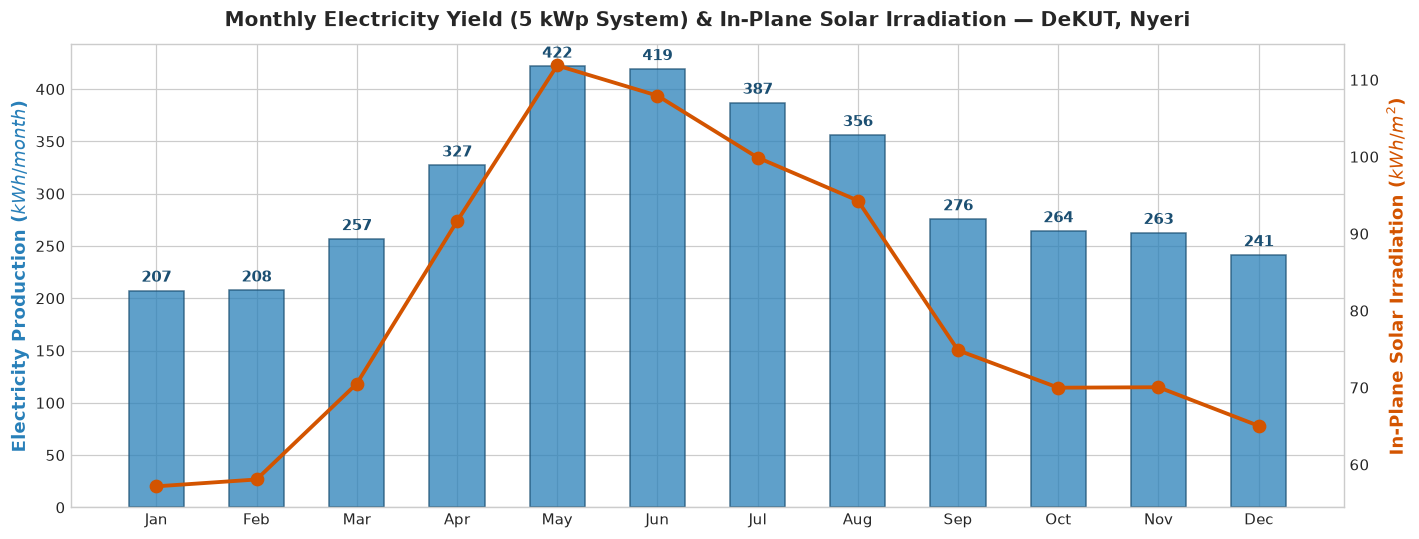

In [8]:
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
m_df = monthly_yield_df.copy()
m_df['month_name'] = [month_names[int(m)-1] for m in m_df['month']]

fig, ax1 = plt.subplots(figsize=(13, 5))

# Monthly electricity generation bars
color_bar = '#2980b9'
bars = ax1.bar(m_df['month_name'], m_df['E_m'], color=color_bar, alpha=0.75, width=0.55, edgecolor='#1b4f72', label='Monthly Electricity Generated ($E_m$, kWh)')
ax1.set_ylabel('Electricity Production ($kWh/month$)', color=color_bar, fontsize=12, fontweight='bold')
ax1.set_title('Monthly Electricity Yield (5 kWp System) & In-Plane Solar Irradiation — DeKUT, Nyeri', fontsize=13, fontweight='bold', pad=12)

# Add value labels above bars
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 5, f"{yval:.0f}", ha='center', va='bottom', fontsize=10, fontweight='bold', color='#1b4f72')

# In-plane solar irradiation on secondary axis
ax2 = ax1.twinx()
color_line = '#d35400'
ax2.plot(m_df['month_name'], m_df['H(i)_m'], color=color_line, marker='o', linewidth=2.5, markersize=8, label='In-Plane Irradiation ($H_m$, $kWh/m^2$)')
ax2.set_ylabel('In-Plane Solar Irradiation ($kWh/m^2$)', color=color_line, fontsize=12, fontweight='bold')
ax2.grid(False)

plt.tight_layout()
plt.show()


## 6. Typical Meteorological Year (TMY) Analysis (`tmy`)

A **Typical Meteorological Year (TMY)** consists of 8,760 hourly values representing a synthetic year constructed from the most representative historical months. TMY files are the global industry standard for building thermal modeling (EnergyPlus) and renewable microgrid sizing (SAM, HOMER).

`query_pvgis_tmy(...)` synthesizes a complete TMY dataset in 1 line of code.

In [9]:
# Download a complete 8,760-hour Typical Meteorological Year (TMY) for DeKUT, Nyeri
tmy_df = query_pvgis_tmy(lat=DEKUT_NYERI_LAT, lon=DEKUT_NYERI_LON, database="PVGIS-SARAH3")

print(f"TMY Dataset shape: {tmy_df.shape} (8,760 hours of representative weather)")
display(tmy_df.head(8))


TMY Dataset shape: (8760, 9) (8,760 hours of representative weather)


,t2m,rh,ghi,dni,dhi,infra_red,wind_speed,wind_dir,surface_pressure
time,,,,,,,,,
2015-01-01 00:00:00+00:00,12.98,79.31,0.0,0.00,0.0,286.50,1.32,336.0,80890.0
2015-01-01 01:00:00+00:00,12.96,77.79,0.0,0.00,0.0,283.91,1.33,336.0,80900.0
2015-01-01 02:00:00+00:00,12.94,76.28,0.0,0.00,0.0,281.33,1.35,332.0,80940.0
2015-01-01 03:00:00+00:00,12.92,74.76,0.0,0.00,0.0,278.74,1.37,328.0,81010.0
2015-01-01 04:00:00+00:00,12.90,73.25,96.0,474.49,37.0,276.16,1.39,326.0,81040.0
2015-01-01 05:00:00+00:00,12.88,71.73,349.0,757.72,79.0,273.57,1.40,322.0,81100.0
2015-01-01 06:00:00+00:00,12.86,70.22,598.0,886.17,98.0,270.98,1.42,321.0,81120.0
2015-01-01 07:00:00+00:00,12.85,68.70,806.0,944.34,113.0,268.40,1.44,329.0,81090.0


### Plot 4: TMY Diurnal & Seasonal Solar Irradiance Heatmap
A 2D matrix visualizing solar flux ($W/m^2$) across all 24 hours of the day and all 12 months of the Typical Meteorological Year at DeKUT.

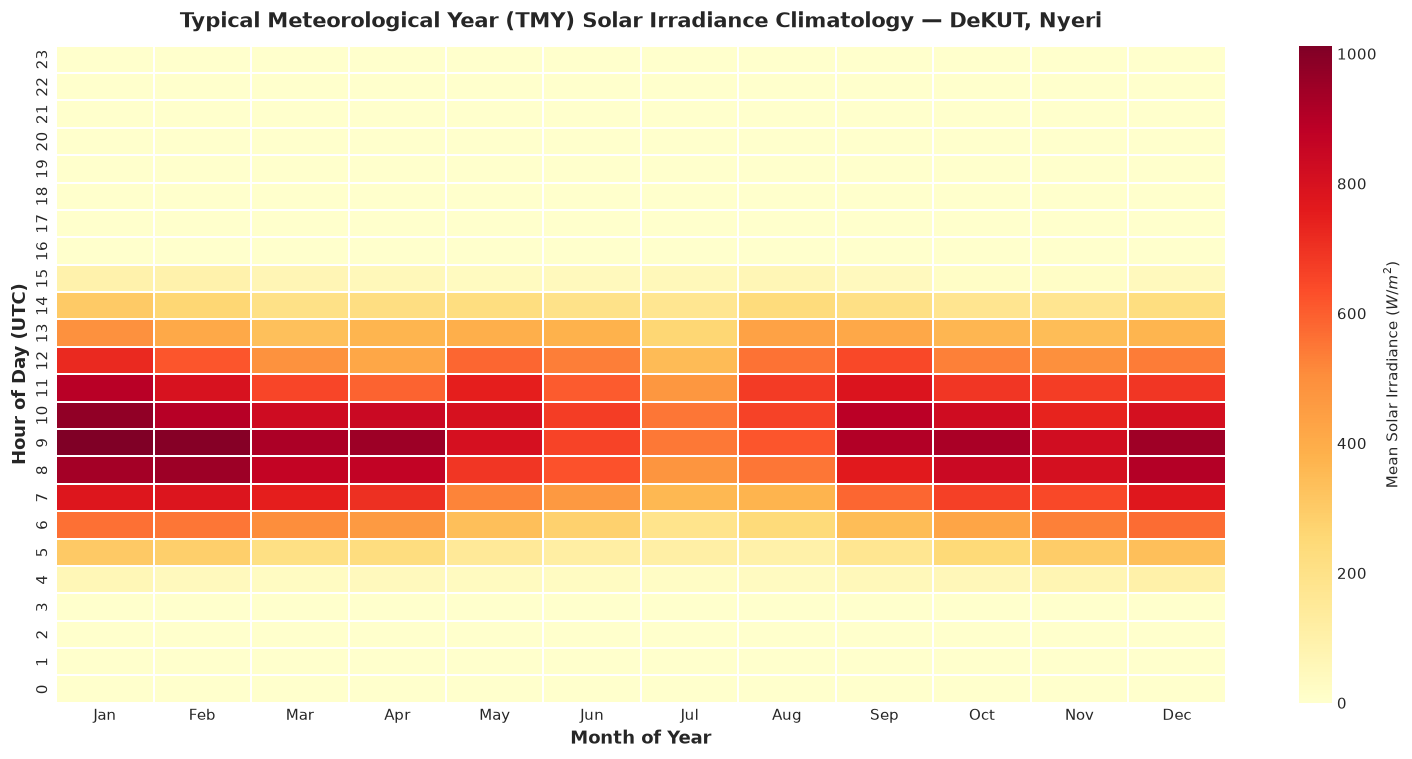

In [10]:
# Build Hour x Month diurnal solar matrix
tmy_matrix = tmy_df.copy()
tmy_matrix['hour'] = tmy_matrix.index.hour
tmy_matrix['month'] = tmy_matrix.index.month
heatmap_data = tmy_matrix.pivot_table(index='hour', columns='month', values='ghi', aggfunc='mean')
heatmap_data.columns = month_names

fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(heatmap_data, cmap='YlOrRd', cbar_kws={'label': 'Mean Solar Irradiance ($W/m^2$)'}, ax=ax, linewidths=0.2)
ax.set_title('Typical Meteorological Year (TMY) Solar Irradiance Climatology — DeKUT, Nyeri', fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Hour of Day (UTC)', fontsize=12, fontweight='bold')
ax.set_xlabel('Month of Year', fontsize=12, fontweight='bold')
ax.invert_yaxis()

plt.tight_layout()
plt.show()


## 7. Multi-Location Spatial Comparison Across Kenya

PVGIS supports parallel multi-point queries. Let's benchmark the annual solar yield and PV potential of **DeKUT (Nyeri)** against three contrasting Kenyan eco-zones:
1. **DeKUT (Nyeri)**: Cool high-altitude university campus (`-0.398, 36.958`, 1,780m)
2. **Nairobi**: Highland urban capital (`-1.286, 36.817`, 1,660m)
3. **Lodwar (Turkana)**: Arid northern desert, extreme solar resource (`3.119, 35.597`, 470m)
4. **Mombasa**: Coastal humid tropical plain (`-4.030, 39.600`, 50m)

In [11]:
benchmark_sites = [
    {"name": "DeKUT (Nyeri Highland)", "lat": DEKUT_NYERI_LAT, "lon": DEKUT_NYERI_LON},
    {"name": "Nairobi (Urban)", "lat": -1.286, "lon": 36.817},
    {"name": "Lodwar (Turkana Desert)", "lat": 3.119, "lon": 35.597},
    {"name": "Mombasa (Coast)", "lat": -4.030, "lon": 39.600},
]

# Run PVcalc simulation for a 1 kWp system across all 4 sites
site_comparisons = []
for site in benchmark_sites:
    res = simulate_pvgis_pv(lat=site["lat"], lon=site["lon"], peakpower=1.0, optimalangles=True)
    t = res["totals"]
    opt = res["optimal_angles"]
    site_comparisons.append({
        "Location": site["name"],
        "Annual Yield (kWh/kWp)": t.get("E_y"),
        "Daily Yield (kWh/day)": t.get("E_d"),
        "Annual In-Plane Solar (kWh/m^2)": t.get("H(i)_y"),
        "System Loss (%)": t.get("l_total"),
        "Optimal Tilt (°)": opt.get("slope", {}).get("value"),
    })

comparison_df = pd.DataFrame(site_comparisons)
display(comparison_df)


,Location,Annual Yield (kWh/kWp),Daily Yield (kWh/day),Annual In-Plane Solar (kWh/m^2),System Loss (%),Optimal Tilt (°)
0,DeKUT (Nyeri Highland),725.23,1.99,971.18,-25.33,89
1,Nairobi (Urban),697.30,1.91,946.86,-26.36,89
2,Lodwar (Turkana Desert),1815.86,4.97,2446.58,-25.78,4
3,Mombasa (Coast),570.01,1.56,788.96,-27.75,0


### Plot 5: Regional Photovoltaic Potential Benchmark Across Kenya
Comparing specific PV generation ($kWh/kWp/year$) across the four benchmark locations.

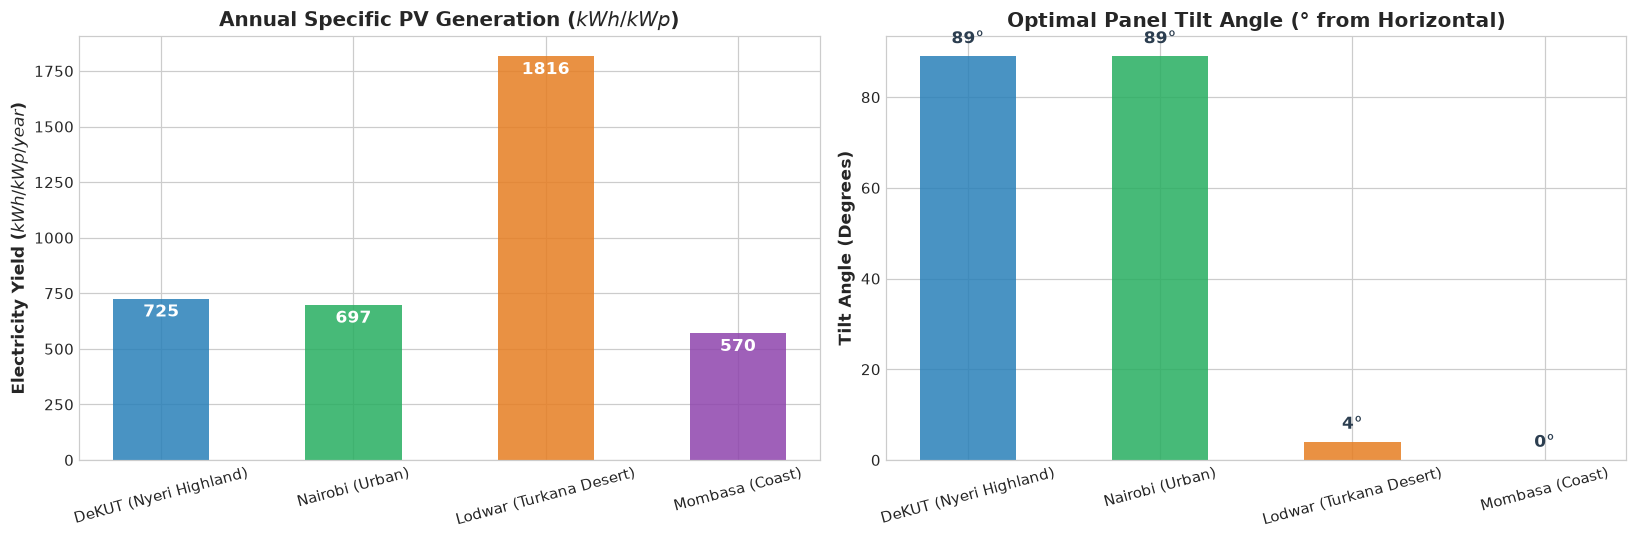

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Bar chart of Annual Energy Yield
colors = ['#2980b9', '#27ae60', '#e67e22', '#8e44ad']
bars = ax1.bar(comparison_df['Location'], comparison_df['Annual Yield (kWh/kWp)'], color=colors, alpha=0.85, width=0.5)
ax1.set_title('Annual Specific PV Generation ($kWh/kWp$)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Electricity Yield ($kWh/kWp/year$)', fontsize=11, fontweight='bold')
ax1.tick_params(axis='x', rotation=15)
for bar in bars:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, y - 60, f"{y:.0f}", ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Bar chart of Optimal Tilt Angles
bars2 = ax2.bar(comparison_df['Location'], comparison_df['Optimal Tilt (°)'], color=colors, alpha=0.85, width=0.5)
ax2.set_title('Optimal Panel Tilt Angle (° from Horizontal)', fontsize=13, fontweight='bold')
ax2.set_ylabel('Tilt Angle (Degrees)', fontsize=11, fontweight='bold')
ax2.tick_params(axis='x', rotation=15)
for bar in bars2:
    y = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, y + 2, f"{y:.0f}°", ha='center', va='bottom', color='#2c3e50', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()


## 8. Topographical Shading & Horizon Profile (`printhorizon`)

Near Mount Kenya and the Aberdare Range, local topography can cause early sunrise or late sunset shading. PVGIS provides the `printhorizon` tool to extract the 360-degree horizon elevation angle profile derived from digital elevation models (DEMs).

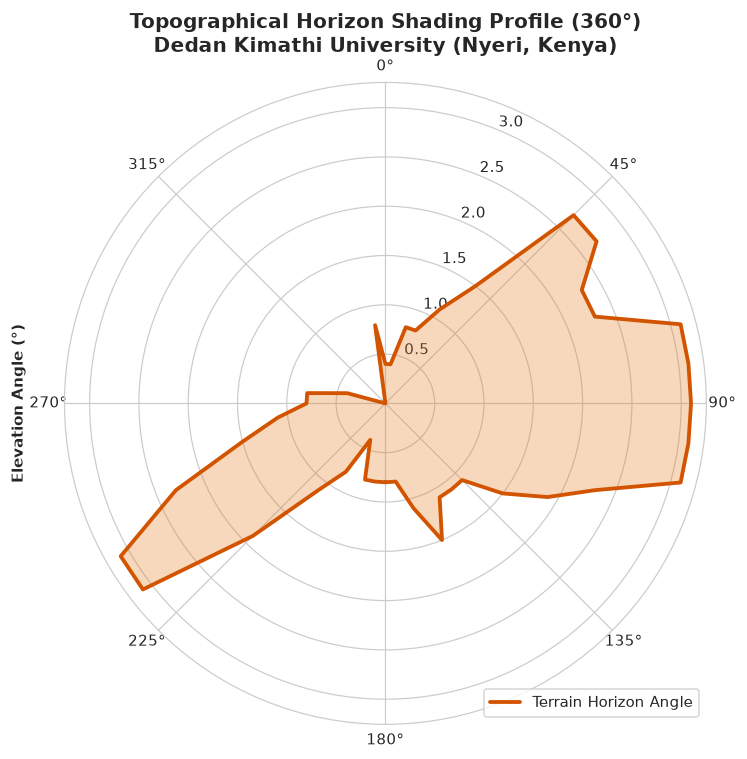

In [13]:
client = PVGIS()
horizon_df = client.horizon(lat=DEKUT_NYERI_LAT, lon=DEKUT_NYERI_LON)

# Polar plot of topographical shading around DeKUT
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})

# Convert azimuth degrees to radians (0 = North)
theta = np.deg2rad(horizon_df['A'])
heights = horizon_df['H_hor']

ax.plot(theta, heights, color='#d35400', linewidth=2.5, label='Terrain Horizon Angle')
ax.fill(theta, heights, color='#e67e22', alpha=0.3)
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1) # Clockwise (N-E-S-W)
ax.set_title('Topographical Horizon Shading Profile (360°)\nDedan Kimathi University (Nyeri, Kenya)', fontsize=13, fontweight='bold', pad=20)
ax.set_ylabel('Elevation Angle (°)', labelpad=25, fontsize=10, fontweight='bold')
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()


## 9. Performance & Parquet Caching Benchmark

The wrapper incorporates transparent on-disk caching via Parquet files in `./mw_cache`:
1. Every query generates a SHA-256 fingerprint based on coordinates, database, years, and parameters.
2. Subsequent calls read directly from disk with sub-millisecond latency.
3. This guarantees reproducible, offline-capable analysis and respects EU JRC server capacity.

In [14]:
import time

# Repeated call - hits local Parquet cache
t0 = time.time()
cached_df = query_pvgis(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    start_date="2023-01-01",
    end_date="2023-01-07",
    variables=["ghi", "temp"]
)
t_elapsed = (time.time() - t0) * 1000

print(f"Parquet cache hit retrieved in: {t_elapsed:.2f} ms!")


Parquet cache hit retrieved in: 615.74 ms!


## 10. Summary & Academic Citation

The `masharikiweather.wrappers.pvgis` module provides:
1. **Zero Key Needed:** Public REST API accessible out-of-the-box.
2. **EUMETSAT CM SAF SARAH-3:** Latest satellite generation (2005–2023, 0.05° resolution).
3. **Integrated PV Simulation:** Electrical generation ($P$), annual yield ($E_y$), and automated tilt angle optimization.
4. **Typical Meteorological Years:** 8,760-hour synthetic years for building energy modeling.
5. **Topographical Shading:** 360-degree horizon obstruction angles.

### How to Cite PVGIS in Publications:
If using PVGIS data in academic research or technical engineering reports, please cite:
> Huld, T., Müller, R., & Gambardella, A. (2012). A new solar radiation database for estimating PV performance in Europe and Africa. *Solar Energy*, 86(6), 1803-1815.
> European Commission Joint Research Centre (JRC). Photovoltaic Geographical Information System (PVGIS).
> Website: https://joint-research-centre.ec.europa.eu/photovoltaic-geographical-information-system-pvgis_en
